<a href="https://colab.research.google.com/github/ashutoshdubey63078-cloud/CodeAlpha_ProjectName/blob/main/plant_disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import mode
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from imblearn.over_sampling import RandomOverSampler
%matplotlib inline

In [1]:
import kagglehub
import tensorflow as tf

# 1. Download the dataset first
download_path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
print("Dataset downloaded to:", download_path)

# 2. Update the path to point to the downloaded dataset folder structure
path = download_path

train = tf.keras.utils.image_dataset_from_directory(
    f"{path}/plantvillage dataset/color", image_size=(224,224), batch_size=32, validation_split=0.2, subset="training", seed=42)
val = tf.keras.utils.image_dataset_from_directory(
    f"{path}/plantvillage dataset/color", image_size=(224,224), batch_size=32, validation_split=0.2, subset="validation", seed=42)
n = len(train.class_names)

# 3. Explicitly map data to cast images to float32 and rescale them to [-1, 1]
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_image(image, label):
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1.0  # Equivalent to Rescaling(1./127.5, offset=-1)
    return image, label

train = train.map(preprocess_image, num_parallel_calls=AUTOTUNE)
val = val.map(preprocess_image, num_parallel_calls=AUTOTUNE)

# 4. Define base and sequential model
base = tf.keras.applications.MobileNetV2(
    input_shape=(224,224,3), include_top=False, weights="imagenet")
base.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    base,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(n, activation="softmax")])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# Use ModelCheckpoint to save the model after each epoch automatically
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="plant_model.keras",
    save_best_only=True,
    monitor="val_loss",
    mode="min",
    verbose=1
)

model.fit(train, validation_data=val, epochs=5, callbacks=[checkpoint])
model.save("plant_model.keras")

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Dataset downloaded to: /kaggle/input/plantvillage-dataset
Found 54305 files belonging to 38 classes.
Using 43444 files for training.
Found 54305 files belonging to 38 classes.
Using 10861 files for validation.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.7531 - loss: 0.9477
Epoch 1: val_loss improved from None to 0.22217, saving model to plant_model.keras

Epoch 1: finished saving model to plant_model.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 191s 133ms/step - accuracy: 0.8615 - loss: 0.5017 - val_accuracy: 0.9354 - val_loss: 0.2222
Epoch 2/5
1357/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.9256 - loss: 0.2418
Epoch 2: val_loss improved from 0.22217 to 0.16969, saving model to plant_model.keras

Epoch 2: finished saving model to plant_model.keras
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 97s 72ms/step - accuracy: 0.9293 - loss: 0.2261 - val_accura

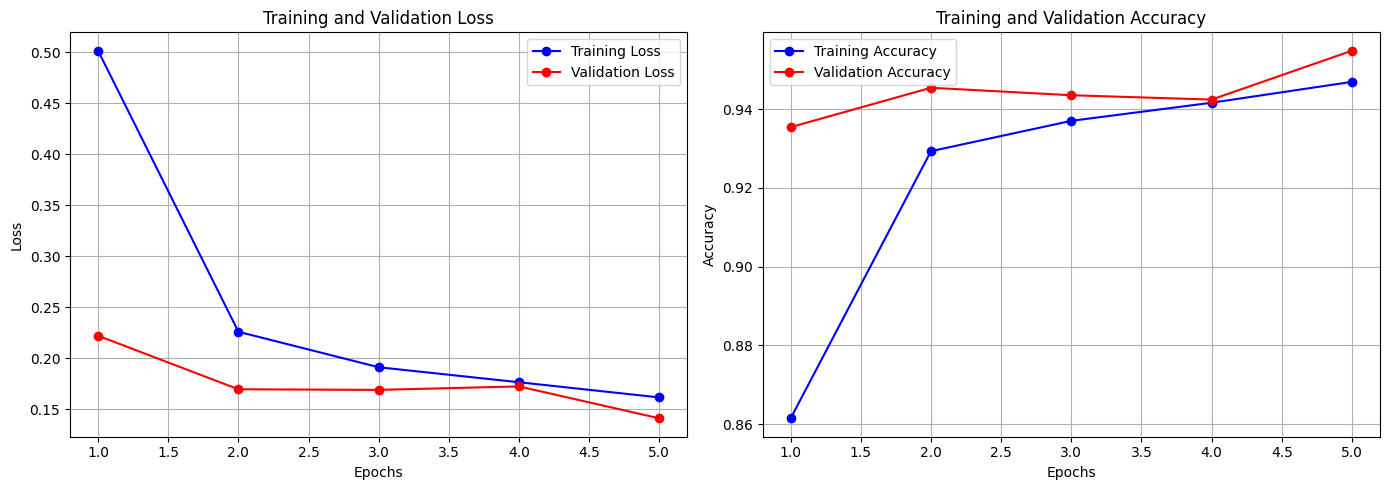

In [10]:
import matplotlib.pyplot as plt

# Since model.fit() was run without saving the history object (e.g., history = model.fit(...)),
# we manually parse the history values printed in the console output to plot them.

history_data = {
    'accuracy': [0.8615, 0.9293, 0.9370, 0.9416, 0.9469],
    'loss': [0.5017, 0.2261, 0.1913, 0.1766, 0.1617],
    'val_accuracy': [0.9354, 0.9454, 0.9435, 0.9424, 0.9548],
    'val_loss': [0.2222, 0.1697, 0.1691, 0.1725, 0.1412]
}

epochs = range(1, len(history_data['accuracy']) + 1)

# Create the plots
plt.figure(figsize=(14, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, history_data['loss'], 'bo-', label='Training Loss')
plt.plot(epochs, history_data['val_loss'], 'ro-', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, history_data['accuracy'], 'bo-', label='Training Accuracy')
plt.plot(epochs, history_data['val_accuracy'], 'ro-', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [6]:
# Run this cell to manually save the model immediately if it is still in your kernel's memory
try:
    if 'model' in globals():
        model.save("plant_model.keras")
        print("Successfully saved model to plant_model.keras manually!")
    else:
        print("No active 'model' variable found in memory. Please run the training cell above.")
except Exception as e:
    print("Error saving model:", e)

try:
    import os
    print("Is plant_model.keras in directory?", os.path.exists("plant_model.keras"))
except Exception as e:
    print("Error checking directory:", e)

No active 'model' variable found in memory. Please run the training cell above.
Is plant_model.keras in directory? False


In [2]:
import os

model_filename = 'plant_model.keras'
exists = os.path.exists(model_filename)

print(f"Checking for model file...")
print(f"File '{model_filename}' exists: {exists}")
if exists:
    print(f"File size: {os.path.getsize(model_filename) / (1024 * 1024):.2f} MB")
else:
    print("The file has not appeared yet. Please make sure the training cell has finished at least one epoch.")

Checking for model file...
File 'plant_model.keras' exists: True
File size: 9.73 MB


In [4]:
import tensorflow as tf

# Load the saved model back into memory
model = tf.keras.models.load_model('plant_model.keras')
print("Model successfully loaded back into memory!")

# Display the model summary to confirm the architecture
model.summary()

Model successfully loaded back into memory!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,404,020 (9.17 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 97,358 (380.31 KB)

Using local sample image: /kaggle/input/plantvillage-dataset/plantvillage dataset/color/Tomato___Late_blight/82090f30-20fa-4c5e-9bcc-9cfe7d64b56a___RS_Late.B 5395.JPG
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


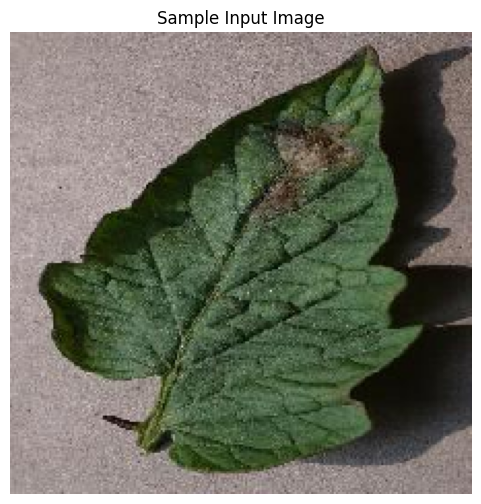


--- Top 3 Model Predictions ---
Tomato___Target_Spot: 59.10%
Tomato___Spider_mites Two-spotted_spider_mite: 16.21%
Tomato___Late_blight: 9.62%


In [9]:
import os
import glob
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Find a local image from the validation dataset to avoid external network issues
dataset_dir = "/kaggle/input/plantvillage-dataset/plantvillage dataset/color"
image_paths = glob.glob(os.path.join(dataset_dir, "*/*.JPG")) + glob.glob(os.path.join(dataset_dir, "*/*.jpg"))

if not image_paths:
    raise FileNotFoundError("No images found in the dataset directory. Ensure the dataset is downloaded.")

# Let's select a representative sample image from the local dataset
sample_image_path = image_paths[100]  # Just picking an arbitrary sample image

print(f"Using local sample image: {sample_image_path}")

# 2. Load and preprocess the image
img = tf.keras.utils.load_img(sample_image_path, target_size=(224, 224))
img_array = tf.keras.utils.img_to_array(img)

# Standardize/Rescale the pixel values to [-1, 1] matching MobileNetV2's preprocessing
img_preprocessed = (img_array / 127.5) - 1.0
img_batch = np.expand_dims(img_preprocessed, axis=0)

# 3. Retrieve class labels dynamically from the dataset directory structure
# We sort them alphabetically to match the behavior of image_dataset_from_directory
class_names = sorted([d for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d))])

# Save classes.json for any other cells that might expect it
with open("classes.json", "w") as f:
    json.dump(class_names, f)

# 4. Perform the prediction
predictions = model.predict(img_batch)[0]
top_3_indices = np.argsort(predictions)[-3:][::-1]

# 5. Display the image and predictions
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis('off')
plt.title("Sample Input Image")
plt.show()

print("\n--- Top 3 Model Predictions ---")
for idx in top_3_indices:
    print(f"{class_names[idx]}: {predictions[idx] * 100:.2f}%")

In [12]:
import tensorflow as tf

# Re-create the validation dataset generator with the original parameters to ensure evaluation consistency
download_path = "/kaggle/input/plantvillage-dataset"
val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{download_path}/plantvillage dataset/color",
    image_size=(224, 224),
    batch_size=32,
    validation_split=0.2,
    subset="validation",
    seed=42
)

# Map and preprocess validation images (scaling to [-1, 1])
AUTOTUNE = tf.data.AUTOTUNE
def preprocess_image(image, label):
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1.0
    return image, label

val_ds_preprocessed = val_ds.map(preprocess_image, num_parallel_calls=AUTOTUNE)

# Load the saved model if not already loaded in memory
if 'model' not in globals():
    model = tf.keras.models.load_model('plant_model.keras')

# Evaluate the model on the full preprocessed validation dataset
eval_results = model.evaluate(val_ds_preprocessed)
print(f"\nFull Validation Loss: {eval_results[0]:.4f}")
print(f"Full Validation Accuracy: {eval_results[1] * 100:.2f}%")

Found 54305 files belonging to 38 classes.
Using 10861 files for validation.
340/340 ━━━━━━━━━━━━━━━━━━━━ 22s 57ms/step - accuracy: 0.9548 - loss: 0.1412

Full Validation Loss: 0.1412
Full Validation Accuracy: 95.48%


In [2]:
import json
import kagglehub
import tensorflow as tf

# 1. Locate the downloaded dataset
download_path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")

# 2. Briefly load the dataset structure to retrieve class_names
temp_dataset = tf.keras.utils.image_dataset_from_directory(
    f"{download_path}/plantvillage dataset/color",
    image_size=(224,224),
    batch_size=32
)

# 3. Save the class names to classes.json
json.dump(temp_dataset.class_names, open("classes.json", "w"))
print("Saved class names to classes.json!")

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Found 54305 files belonging to 38 classes.
Saved class names to classes.json!


In [11]:
!pip install gradio -q
import gradio as gr, json, tensorflow as tf
import os

model_path = "plant_model.keras"
if not os.path.exists(model_path):
    raise FileNotFoundError("plant_model.keras not found! Please ensure your training cell (COByk1gz_qAk) runs to completion to save the model file.")

# Load the saved model and classes
model = tf.keras.models.load_model(model_path)
classes = json.load(open("classes.json"))

def predict(img):
    # 1. Resize the image to 224x224
    img = tf.image.resize(img, (224, 224))
    # 2. Rescale the image from [0, 255] to [-1, 1] to match the MobileNetV2 preprocessing pipeline
    img = (img / 127.5) - 1.0
    # 3. Predict
    p = model.predict(tf.expand_dims(img, 0))[0]
    # Map the top 3 prediction probabilities to their respective class labels
    return {classes[i]: float(p[i]) for i in p.argsort()[-3:][::-1]}

# Launch the Gradio web interface with a shareable public link
demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(label="Upload Plant Leaf Image"),
    outputs=gr.Label(num_top_classes=3, label="Predictions"),
    title="Plant Disease Classification App",
    description="Upload a close-up image of a plant leaf to classify the plant species and detect disease if present."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f5d656a705d0963957.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
